In [1]:
#packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, recall_score

In [2]:
#path
MASTER_PATH = r"D:\machine learning for finance literature\cleaned x variables (final one)\master_panel_v5.csv"
DV_PATH = r"D:\machine learning for finance literature\cleaned x variables (final one)\portfolio_investment_final.csv"
FEATURES = [
    "exchange_rate", "reserves_pct_gdp", "gdp_growth_yoy", "m2_growth_yoy",
    "market_cap_gdp_ratio", "Interest_Rate", "Stock_Return_Percent",
    "Stock_Volatility", "us_dollar_index", "VIX", "Fed_Funds_Rate",
    "Brent_Oil_Price", "current_account_pct_gdp",
]
TRAIN_FRACTION = 0.80            # matches the logit script's 80/20 split exactly
WALK_FORWARD_START = "2010Q1"    # matches the logit quarterly walk-forward exactly


def flag_reversals_percentile(series, pct=0.10, min_periods=12):
    flags = pd.Series(index=series.index, dtype=float)
    for i in range(len(series)):
        if i + 1 < min_periods:
            flags.iloc[i] = np.nan
        else:
            threshold = series.iloc[: i + 1].quantile(pct)
            flags.iloc[i] = int(series.iloc[i] <= threshold)
    return flags


In [3]:
#cleaning
X_df = pd.read_csv(MASTER_PATH)
dv_df = pd.read_csv(DV_PATH)
dv_df["portfolio_investment"] = pd.to_numeric(
    dv_df["portfolio_investment"].astype(str).str.replace(",", "", regex=False), errors="coerce"
)
dv_df = dv_df.dropna(subset=["portfolio_investment"]).sort_values(["country", "quarter"])
dv_df["reversal"] = dv_df.groupby("country")["portfolio_investment"].transform(
    lambda s: flag_reversals_percentile(s.reset_index(drop=True), pct=0.10).values
)

for col in FEATURES:
    if col in X_df.columns:
        X_df[col] = pd.to_numeric(X_df[col].astype(str).str.replace(",", "", regex=False), errors="coerce")
X_df = X_df.sort_values(["country", "quarter"])
for col in FEATURES:
    X_df[col] = X_df.groupby("country")[col].shift(1)

panel = X_df.merge(dv_df[["country", "quarter", "reversal"]], on=["country", "quarter"], how="inner")
use = panel.dropna(subset=FEATURES + ["reversal"]).reset_index(drop=True)

In [4]:
#creating quarter
use["quarter_dt"] = pd.PeriodIndex(use["quarter"], freq="Q").to_timestamp()
use = use.sort_values("quarter_dt").reset_index(drop=True)

print("Observations:", len(use))
print("Event rate:", round(use["reversal"].mean(), 3))


Observations: 1555
Event rate: 0.166


In [5]:
#random forest 80/20
unique_quarters = use["quarter_dt"].sort_values().unique()
cutoff_index = int(len(unique_quarters) * TRAIN_FRACTION)
cutoff_date = unique_quarters[cutoff_index]

train_df = use[use["quarter_dt"] < cutoff_date].reset_index(drop=True)
test_df = use[use["quarter_dt"] >= cutoff_date].reset_index(drop=True)

print(f"\nCutoff date: {pd.Timestamp(cutoff_date).date()}")
print(f"Train: {len(train_df)} obs, {train_df['quarter_dt'].min().date()} to {train_df['quarter_dt'].max().date()}, "
      f"event rate={train_df['reversal'].mean():.3f}")
print(f"Test:  {len(test_df)} obs, {test_df['quarter_dt'].min().date()} to {test_df['quarter_dt'].max().date()}, "
      f"event rate={test_df['reversal'].mean():.3f}")

X_train = train_df[FEATURES]
y_train = train_df["reversal"].astype(int)
X_test = test_df[FEATURES]
y_test = test_df["reversal"].astype(int)



Cutoff date: 2021-04-01
Train: 1234 obs, 2002-10-01 to 2021-01-01, event rate=0.159
Test:  321 obs, 2021-04-01 to 2025-10-01, event rate=0.193


In [10]:
#loop over trees
n_grid = range(20, 301, 10)

test_error_rf = []
oob_error_rf = []
test_f1_rf = []
test_auroc_rf = []

for n in n_grid:
    rf = RandomForestClassifier(
        n_estimators=n,
        max_features="sqrt",
        min_samples_leaf=20,   # scaled down from the notebook's 50, given our much smaller N (~1088 train rows vs ~3400)
        bootstrap=True,
        oob_score=True,
        class_weight="balanced",  # accounts for the ~17% event rate, same spirit as this project's balancing elsewhere
        random_state=0,
        n_jobs=-1,
    )

    rf.fit(X_train, y_train)
    #test error and oob 
    pred_test = rf.predict(X_test)
    prob_test = rf.predict_proba(X_test)[:, 1]
    test_error_rf.append(1 - accuracy_score(y_test, pred_test))
    test_f1_rf.append(f1_score(y_test, pred_test, zero_division=0))
    test_auroc_rf.append(roc_auc_score(y_test, prob_test))

    # OOB error (built-in out-of-bag estimate, no separate validation set needed)
    oob_error_rf.append(1 - rf.oob_score_)
    print("Completed iterations:", len(test_auroc_rf), "/", len(list(n_grid)))



Completed iterations: 1 / 29
Completed iterations: 2 / 29
Completed iterations: 3 / 29
Completed iterations: 4 / 29
Completed iterations: 5 / 29
Completed iterations: 6 / 29
Completed iterations: 7 / 29
Completed iterations: 8 / 29
Completed iterations: 9 / 29
Completed iterations: 10 / 29
Completed iterations: 11 / 29
Completed iterations: 12 / 29
Completed iterations: 13 / 29
Completed iterations: 14 / 29
Completed iterations: 15 / 29
Completed iterations: 16 / 29
Completed iterations: 17 / 29
Completed iterations: 18 / 29
Completed iterations: 19 / 29
Completed iterations: 20 / 29
Completed iterations: 21 / 29
Completed iterations: 22 / 29
Completed iterations: 23 / 29
Completed iterations: 24 / 29
Completed iterations: 25 / 29
Completed iterations: 26 / 29
Completed iterations: 27 / 29
Completed iterations: 28 / 29
Completed iterations: 29 / 29



Naive baseline error (always predict majority class): 0.1659
Best test error: 0.2991 at n_estimators=270
Best OOB error:  0.2350 at n_estimators=110
Test F1 at that same n_estimators point: 0.1429
Test AUROC at that same n_estimators point: 0.3701
Best test AUROC: 0.4115 at n_estimators=20
Mean test AUROC across all tree counts: 0.3743 (+/- 0.0090)


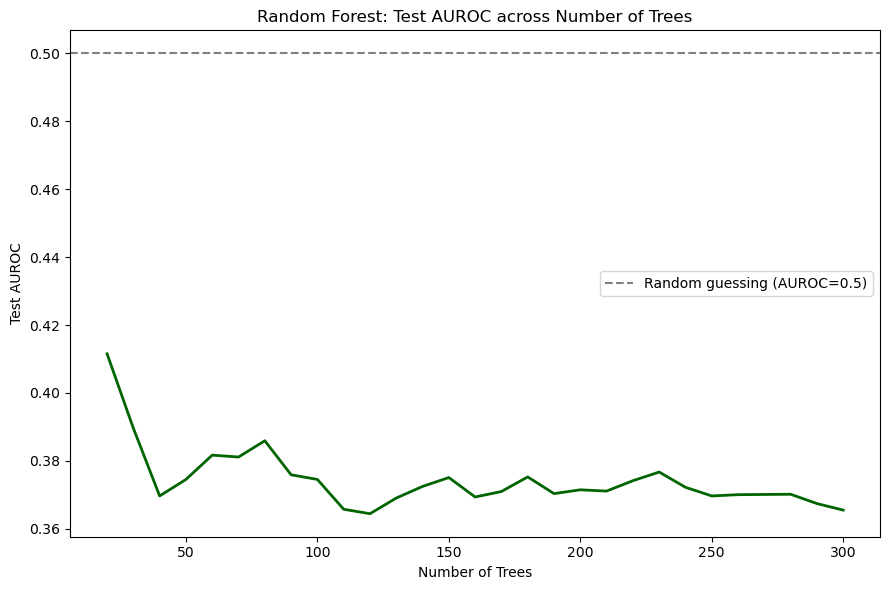

In [11]:
#summary, AUROC
naive_error = 1 - max(use["reversal"].mean(), 1 - use["reversal"].mean())
print(f"\nNaive baseline error (always predict majority class): {naive_error:.4f}")
print(f"Best test error: {min(test_error_rf):.4f} at n_estimators={list(n_grid)[np.argmin(test_error_rf)]}")
print(f"Best OOB error:  {min(oob_error_rf):.4f} at n_estimators={list(n_grid)[np.argmin(oob_error_rf)]}")
print(f"Test F1 at that same n_estimators point: {test_f1_rf[np.argmin(test_error_rf)]:.4f}")
print(f"Test AUROC at that same n_estimators point: {test_auroc_rf[np.argmin(test_error_rf)]:.4f}")
print(f"Best test AUROC: {max(test_auroc_rf):.4f} at n_estimators={list(n_grid)[np.argmax(test_auroc_rf)]}")
print(f"Mean test AUROC across all tree counts: {np.mean(test_auroc_rf):.4f} (+/- {np.std(test_auroc_rf):.4f})")

plt.figure(figsize=(9, 6))
plt.plot(n_grid, test_auroc_rf, color="darkgreen", linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--", label="Random guessing (AUROC=0.5)")
plt.xlabel("Number of Trees")
plt.ylabel("Test AUROC")
plt.title("Random Forest: Test AUROC across Number of Trees")
plt.legend()
plt.tight_layout()
plt.savefig("rf_auroc.png", dpi=200)
plt.show()


In [12]:
#Feature importance
rf_final = RandomForestClassifier(
    n_estimators=200, max_features="sqrt", min_samples_leaf=20,
    bootstrap=True, class_weight="balanced", random_state=0, n_jobs=-1,
)
rf_final.fit(X_train, y_train)
importances = pd.Series(rf_final.feature_importances_, index=FEATURES).sort_values(ascending=False)
print("\nFeature importances (Random Forest, n_estimators=200):")
print(importances)



Feature importances (Random Forest, n_estimators=200):
reserves_pct_gdp           0.135786
Fed_Funds_Rate             0.115550
Brent_Oil_Price            0.107508
VIX                        0.085533
us_dollar_index            0.085037
exchange_rate              0.070874
Interest_Rate              0.069095
m2_growth_yoy              0.059881
Stock_Volatility           0.056460
gdp_growth_yoy             0.056228
current_account_pct_gdp    0.055314
market_cap_gdp_ratio       0.055257
Stock_Return_Percent       0.047475
dtype: float64


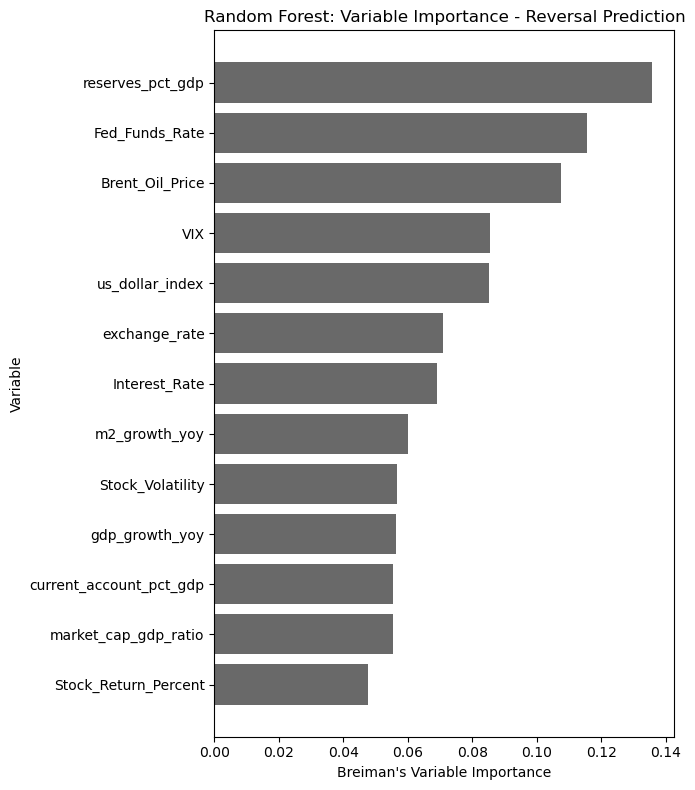

In [13]:
#feature importance plot
importances_sorted = importances.sort_values(ascending=True)  # ascending so biggest bar ends up on top when plotted

plt.figure(figsize=(7, 8))
plt.barh(importances_sorted.index, importances_sorted.values, color="dimgray")
plt.xlabel("Breiman's Variable Importance")
plt.ylabel("Variable")
plt.title("Random Forest: Variable Importance - Reversal Prediction")
plt.tight_layout()
plt.savefig("rf_variable_importance.png", dpi=200)
plt.show()

In [14]:
#randomforest walking forward
wf_start = pd.Period(WALK_FORWARD_START, freq="Q").to_timestamp()
eval_quarters = [q for q in unique_quarters if q >= wf_start]

rows = []
all_true, all_prob, all_pred = [], [], []

for q in eval_quarters:
    tr = use[use["quarter_dt"] < q]
    te = use[use["quarter_dt"] == q]
    if len(te) == 0 or tr["reversal"].nunique() < 2:
        continue

    Xtr = tr[FEATURES]
    ytr = tr["reversal"].astype(int)
    Xte = te[FEATURES]
    yte = te["reversal"].astype(int)

    rf_q = RandomForestClassifier(
        n_estimators=200, max_features="sqrt", min_samples_leaf=20,
        bootstrap=True, class_weight="balanced", random_state=0, n_jobs=-1,
    )
    rf_q.fit(Xtr, ytr)

    pred = rf_q.predict(Xte)
    prob = rf_q.predict_proba(Xte)[:, 1]

    rows.append({
        "quarter": pd.Timestamp(q).to_period("Q").strftime("%YQ%q"),
        "n_obs": len(te),
        "n_reversals": int(yte.sum()),
        "accuracy": accuracy_score(yte, pred),
    })
    all_true.extend(yte)
    all_prob.extend(prob)
    all_pred.extend(pred)

wf = pd.DataFrame(rows)
all_true = np.array(all_true)
all_prob = np.array(all_prob)
all_pred = np.array(all_pred)

print(f"\n=== WALK-FORWARD EVALUATION (Random Forest, from {WALK_FORWARD_START}) ===")
print(f"Quarters evaluated: {len(wf)} "
      f"({wf['quarter'].iloc[0]} to {wf['quarter'].iloc[-1]})")
print(f"Total predictions:  {len(all_true)} (of which {int(all_true.sum())} true reversals)")
print(f"\nAverage prediction accuracy (mean across quarters): {wf['accuracy'].mean():.4f}")
print(f"Pooled accuracy (all obs together):                 {accuracy_score(all_true, all_pred):.4f}")
print(f"Pooled AUROC:                                       {roc_auc_score(all_true, all_prob):.4f}")
print(f"Pooled F1:                                          {f1_score(all_true, all_pred, zero_division=0):.4f}")
print(f"Pooled recall:                                      {recall_score(all_true, all_pred, zero_division=0):.4f}")
print(f"Naive baseline accuracy (always 'no reversal'):     {1 - all_true.mean():.4f}")

print("\n=== Per-quarter accuracy (walk-forward, Random Forest) ===")
print(wf.to_string(index=False))



=== WALK-FORWARD EVALUATION (Random Forest, from 2010Q1) ===
Quarters evaluated: 64 (2010Q1 to 2025Q4)
Total predictions:  1220 (of which 201 true reversals)

Average prediction accuracy (mean across quarters): 0.7140
Pooled accuracy (all obs together):                 0.7148
Pooled AUROC:                                       0.5503
Pooled F1:                                          0.1792
Pooled recall:                                      0.1891
Naive baseline accuracy (always 'no reversal'):     0.8352

=== Per-quarter accuracy (walk-forward, Random Forest) ===
quarter  n_obs  n_reversals  accuracy
 2010Q1     15            2  0.200000
 2010Q2     15            2  0.400000
 2010Q3     15            0  0.666667
 2010Q4     15            1  0.933333
 2011Q1     15            0  0.133333
 2011Q2     17            2  0.176471
 2011Q3     17            4  0.588235
 2011Q4     17            2  0.647059
 2012Q1     17            0  0.764706
 2012Q2     20            3  0.800000
 2012Q3 

In [15]:
wf_export = wf.copy()
wf_export["model"] = "Random Forest"
wf_export.to_csv("walkforward_rf.csv", index=False)
print("\nSaved: walkforward_rf.csv")



Saved: walkforward_rf.csv
